In [ ]:
ViT-Small

Params: 21,571,972.0
GFLOPs: 4.2408

===== FOLD 1/5 =====
Accuracy : 0.9615
Precision: 0.9523
Recall   : 0.9513
F1-Score : 0.9518
RMSE     : 0.5000

===== FOLD 2/5 =====
Accuracy : 0.9542
Precision: 0.9400
Recall   : 0.9412
F1-Score : 0.9404
RMSE     : 0.5287

===== FOLD 3/5 =====
Accuracy : 0.9759
Precision: 0.9684
Recall   : 0.9705
F1-Score : 0.9694
RMSE     : 0.3988

===== FOLD 4/5 =====
Accuracy : 0.9783
Precision: 0.9702
Recall   : 0.9753
F1-Score : 0.9725
RMSE     : 0.3958

===== FOLD 5/5 =====
Accuracy : 0.9711
Precision: 0.9659
Recall   : 0.9658
F1-Score : 0.9657
RMSE     : 0.4136

===== FINAL K-FOLD RESULTS =====
Accuracy  : 0.9682 ± 0.0091
Precision : 0.9594 ± 0.0115
Recall    : 0.9608 ± 0.0127
F1-Score  : 0.9599 ± 0.0121
RMSE      : 0.4474 ± 0.0558


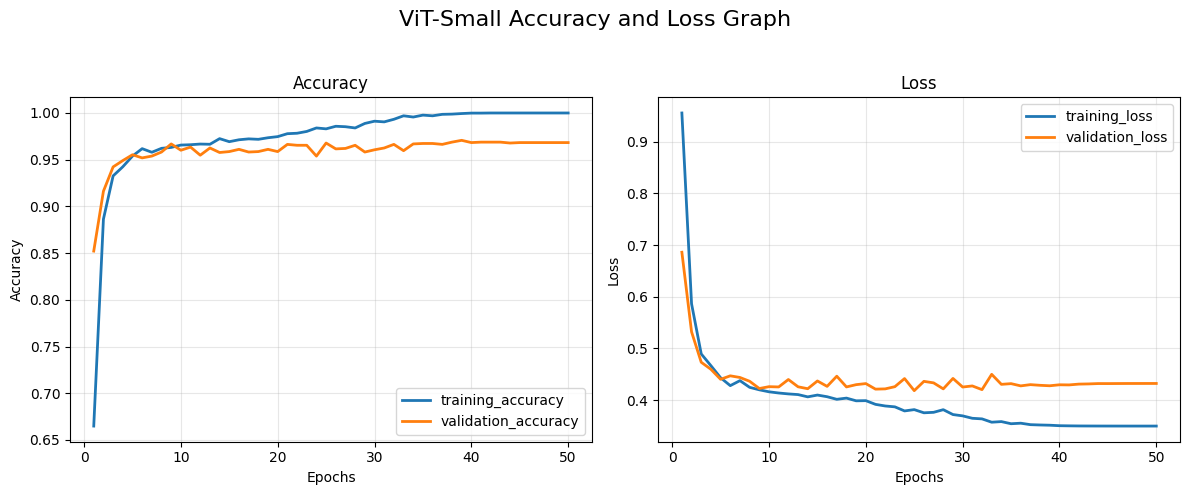

In [6]:
# ViT_Small_KFold.py
# 5-Fold Cross Validation version using ViT-Small (Vision Transformer)
# Reports: Accuracy, Precision, Recall, F1, RMSE, Mean±Std
# Plots: Mean Accuracy and Loss Curves

import math
import os
import matplotlib.pyplot as plt
import numpy as np
import timm
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedKFold
from thop import profile
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

DATA_ROOT = "/workspace/4class/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 1e-4
K_FOLDS = 5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Data Augmentation & Normalization (Standard ImageNet Normalization)
train_tf = transforms.Compose(
    [
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

val_tf = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
targets = np.array(dataset.targets)
NUM_CLASSES = len(dataset.classes)


def get_vit_small_model(num_classes):
    """Instantiates ViT-Small and rewrites the head to match num_classes.

    Set pretrained=True if using transfer learning weights.
    """
    model = timm.create_model(
        "vit_small_patch16_224", pretrained=False, num_classes=num_classes
    )
    return model


# Profile Model Complexity
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
tmp_model = get_vit_small_model(NUM_CLASSES).to(DEVICE)
flops, params = profile(tmp_model, inputs=(dummy,), verbose=False)
print(f"Params: {params:,}")
print(f"GFLOPs: {flops/1e9:.4f}")
del tmp_model, dummy

# K-Fold Variables
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
fold_accs, fold_precs, fold_recs, fold_f1s, fold_rmses = [], [], [], [], []
all_train_acc, all_val_acc = [], []
all_train_loss, all_val_loss = [], []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(np.arange(len(dataset)), targets), start=1
):
    print(f"\n===== FOLD {fold}/{K_FOLDS} =====")

    train_ds = Subset(dataset, train_idx)
    val_ds = Subset(dataset, val_idx)

    train_ds.dataset.transform = train_tf
    val_ds.dataset.transform = val_tf

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

    # Initialize fresh ViT-Small model for this fold
    model = get_vit_small_model(NUM_CLASSES).to(DEVICE)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    hist_tr_acc, hist_val_acc = [], []
    hist_tr_loss, hist_val_loss = [], []

    def run_epoch(loader, train=True):
        model.train() if train else model.eval()
        loss_sum, correct, total = 0, 0, 0
        y_true, y_pred = [], []

        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if train:
                optimizer.zero_grad()

            with torch.set_grad_enabled(train):
                out = model(x)
                loss = criterion(out, y)
                if train:
                    loss.backward()
                    optimizer.step()

            pred = out.argmax(1)
            loss_sum += loss.item()
            correct += (pred == y).sum().item()
            total += y.size(0)

            y_true.extend(y.cpu().numpy())
            y_pred.extend(pred.cpu().numpy())

        return (
            loss_sum / len(loader),
            correct / total,
            np.array(y_true),
            np.array(y_pred),
        )

    for epoch in range(EPOCHS):
        tr_loss, tr_acc, _, _ = run_epoch(train_loader, True)
        val_loss, val_acc, y_true, y_pred = run_epoch(val_loader, False)
        scheduler.step()

        hist_tr_acc.append(tr_acc)
        hist_val_acc.append(val_acc)
        hist_tr_loss.append(tr_loss)
        hist_val_loss.append(val_loss)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))

    fold_accs.append(acc)
    fold_precs.append(prec)
    fold_recs.append(rec)
    fold_f1s.append(f1)
    fold_rmses.append(rmse)

    all_train_acc.append(hist_tr_acc)
    all_val_acc.append(hist_val_acc)
    all_train_loss.append(hist_tr_loss)
    all_val_loss.append(hist_val_loss)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"RMSE     : {rmse:.4f}")

print("\n===== FINAL K-FOLD RESULTS =====")
print(f"Accuracy  : {np.mean(fold_accs):.4f} ± {np.std(fold_accs):.4f}")
print(f"Precision : {np.mean(fold_precs):.4f} ± {np.std(fold_precs):.4f}")
print(f"Recall    : {np.mean(fold_recs):.4f} ± {np.std(fold_recs):.4f}")
print(f"F1-Score  : {np.mean(fold_f1s):.4f} ± {np.std(fold_f1s):.4f}")
print(f"RMSE      : {np.mean(fold_rmses):.4f} ± {np.std(fold_rmses):.4f}")

# ===============================
# Mean Accuracy and Loss Curves
# ===============================
mean_train_acc = np.mean(np.array(all_train_acc), axis=0)
mean_val_acc = np.mean(np.array(all_val_acc), axis=0)
mean_train_loss = np.mean(np.array(all_train_loss), axis=0)
mean_val_loss = np.mean(np.array(all_val_loss), axis=0)

epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 5))

# ---------------- Accuracy ----------------
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    mean_train_acc,
    label="training_accuracy",
    color="tab:blue",
    linewidth=2,
)
plt.plot(
    epochs_range,
    mean_val_acc,
    label="validation_accuracy",
    color="tab:orange",
    linewidth=2,
)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

# ---------------- Loss ----------------
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range,
    mean_train_loss,
    label="training_loss",
    color="tab:blue",
    linewidth=2,
)
plt.plot(
    epochs_range,
    mean_val_loss,
    label="validation_loss",
    color="tab:orange",
    linewidth=2,
)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.suptitle("ViT-Small Accuracy and Loss Graph", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("ViT_Small_Accuracy_Loss_Graph.png", dpi=300, bbox_inches="tight")
plt.show()

In [2]:
pip install timm

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 11.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 12.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 13.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 11.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.6/95.6 kB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.4/83.4 kB 108.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.1/132.1 kB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 97.6 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.6/69.6 kB 66.4 MB/s eta 0:00:00
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.9.0
    Uninstalling typing_extensions-4.9.0:
      Successfully uninstalled typing_extensions-4.9.0
  Attempting uninstall: idna
    Found existing installation: idna 3.6
    Uninstalling idna-3.6:
      Successfully uninstalled idna-3.6
  Attempting uninstall: click
    Found existing installation: click 8.1.7
    Uninstalling click-8.1.7:
      Successfully uninstalled click-8.1.7

[notice] A new release of pip is available: 23.3.2 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
!pip install thop

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com

[notice] A new release of pip is available: 23.3.2 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip


In [ ]:
EfficientNetV2-B0

Params: 4,012,672.0
GFLOPs: 0.4139

===== FOLD 1/5 =====
Accuracy : 0.9736
Precision: 0.9643
Recall   : 0.9708
F1-Score : 0.9667
RMSE     : 0.4013

===== FOLD 2/5 =====
Accuracy : 0.9735
Precision: 0.9638
Recall   : 0.9704
F1-Score : 0.9664
RMSE     : 0.4472

===== FOLD 3/5 =====
Accuracy : 0.9855
Precision: 0.9816
Recall   : 0.9804
F1-Score : 0.9810
RMSE     : 0.3143

===== FOLD 4/5 =====
Accuracy : 0.9807
Precision: 0.9737
Recall   : 0.9779
F1-Score : 0.9756
RMSE     : 0.3401

===== FOLD 5/5 =====
Accuracy : 0.9831
Precision: 0.9782
Recall   : 0.9814
F1-Score : 0.9798
RMSE     : 0.3471

===== FINAL K-FOLD RESULTS =====
Accuracy  : 0.9793 ± 0.0049
Precision : 0.9723 ± 0.0072
Recall    : 0.9762 ± 0.0047
F1-Score  : 0.9739 ± 0.0063
RMSE      : 0.3700 ± 0.0479


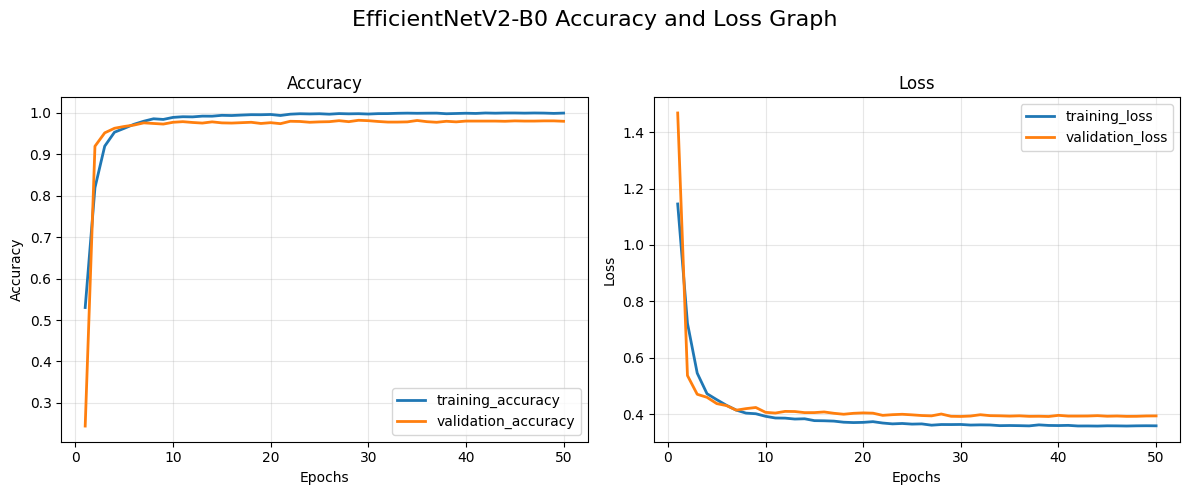

In [7]:
# EfficientNetV2_B0_KFold.py
# 5-Fold Cross Validation version using EfficientNetV2-B0
# Reports: Accuracy, Precision, Recall, F1, RMSE, Mean±Std
# Plots: Mean Accuracy and Loss Curves

import math
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedKFold
from thop import profile
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

DATA_ROOT = "/workspace/4class/"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LR = 1e-4
K_FOLDS = 5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Data Augmentation & Normalization
train_tf = transforms.Compose(
    [
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

val_tf = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

dataset = datasets.ImageFolder(DATA_ROOT, transform=train_tf)
targets = np.array(dataset.targets)
NUM_CLASSES = len(dataset.classes)


def get_efficientnet_v2_b0_model(num_classes):
    """Instantiates EfficientNetV2-B0 and adapts the classifier head."""
    # Using weights=None to train from scratch per design
    model = models.efficientnet_b0(weights=None)

    # Extract the input feature dimension from the classifier
    in_features = model.classifier[1].in_features

    # Replace classifier head for the target number of classes
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.2, inplace=True),
        nn.Linear(in_features, num_classes),
    )
    return model


# Profile Model Complexity
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
tmp_model = get_efficientnet_v2_b0_model(NUM_CLASSES).to(DEVICE)
flops, params = profile(tmp_model, inputs=(dummy,), verbose=False)
print(f"Params: {params:,}")
print(f"GFLOPs: {flops/1e9:.4f}")
del tmp_model, dummy

# K-Fold Variables
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
fold_accs, fold_precs, fold_recs, fold_f1s, fold_rmses = [], [], [], [], []
all_train_acc, all_val_acc = [], []
all_train_loss, all_val_loss = [], []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(np.arange(len(dataset)), targets), start=1
):
    print(f"\n===== FOLD {fold}/{K_FOLDS} =====")

    train_ds = Subset(dataset, train_idx)
    val_ds = Subset(dataset, val_idx)

    train_ds.dataset.transform = train_tf
    val_ds.dataset.transform = val_tf

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

    # Initialize fresh EfficientNetV2-B0 model for this fold
    model = get_efficientnet_v2_b0_model(NUM_CLASSES).to(DEVICE)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    hist_tr_acc, hist_val_acc = [], []
    hist_tr_loss, hist_val_loss = [], []

    def run_epoch(loader, train=True):
        model.train() if train else model.eval()
        loss_sum, correct, total = 0, 0, 0
        y_true, y_pred = [], []

        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if train:
                optimizer.zero_grad()

            with torch.set_grad_enabled(train):
                out = model(x)
                loss = criterion(out, y)
                if train:
                    loss.backward()
                    optimizer.step()

            pred = out.argmax(1)
            loss_sum += loss.item()
            correct += (pred == y).sum().item()
            total += y.size(0)

            y_true.extend(y.cpu().numpy())
            y_pred.extend(pred.cpu().numpy())

        return (
            loss_sum / len(loader),
            correct / total,
            np.array(y_true),
            np.array(y_pred),
        )

    for epoch in range(EPOCHS):
        tr_loss, tr_acc, _, _ = run_epoch(train_loader, True)
        val_loss, val_acc, y_true, y_pred = run_epoch(val_loader, False)
        scheduler.step()

        hist_tr_acc.append(tr_acc)
        hist_val_acc.append(val_acc)
        hist_tr_loss.append(tr_loss)
        hist_val_loss.append(val_loss)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))

    fold_accs.append(acc)
    fold_precs.append(prec)
    fold_recs.append(rec)
    fold_f1s.append(f1)
    fold_rmses.append(rmse)

    all_train_acc.append(hist_tr_acc)
    all_val_acc.append(hist_val_acc)
    all_train_loss.append(hist_tr_loss)
    all_val_loss.append(hist_val_loss)

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"RMSE     : {rmse:.4f}")

print("\n===== FINAL K-FOLD RESULTS =====")
print(f"Accuracy  : {np.mean(fold_accs):.4f} ± {np.std(fold_accs):.4f}")
print(f"Precision : {np.mean(fold_precs):.4f} ± {np.std(fold_precs):.4f}")
print(f"Recall    : {np.mean(fold_recs):.4f} ± {np.std(fold_recs):.4f}")
print(f"F1-Score  : {np.mean(fold_f1s):.4f} ± {np.std(fold_f1s):.4f}")
print(f"RMSE      : {np.mean(fold_rmses):.4f} ± {np.std(fold_rmses):.4f}")

# ===============================
# Mean Accuracy and Loss Curves
# ===============================
mean_train_acc = np.mean(np.array(all_train_acc), axis=0)
mean_val_acc = np.mean(np.array(all_val_acc), axis=0)
mean_train_loss = np.mean(np.array(all_train_loss), axis=0)
mean_val_loss = np.mean(np.array(all_val_loss), axis=0)

epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 5))

# ---------------- Accuracy ----------------
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    mean_train_acc,
    label="training_accuracy",
    color="tab:blue",
    linewidth=2,
)
plt.plot(
    epochs_range,
    mean_val_acc,
    label="validation_accuracy",
    color="tab:orange",
    linewidth=2,
)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

# ---------------- Loss ----------------
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range,
    mean_train_loss,
    label="training_loss",
    color="tab:blue",
    linewidth=2,
)
plt.plot(
    epochs_range,
    mean_val_loss,
    label="validation_loss",
    color="tab:orange",
    linewidth=2,
)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.suptitle("EfficientNetV2-B0 Accuracy and Loss Graph", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("EfficientNetV2_B0_Accuracy_Loss_Graph.png", dpi=300, bbox_inches="tight")
plt.show()